# Hamster Network Analysis

This notebook analyzes the friendships and familylinks between users of the website hamsterster.com

**Data format (.edges):** source hamster, destination hamster

Source: https://networkrepository.com/petster-hamster.php

## Notes:
- Each node represents a user on Hamsterster. 
- Each edge represents a friendship or family connection between two users.
- The number of relationships is given by the length of the dataset, since each line is a family connection or friendship.
- Relationships between users are undirected and unweighted.



## Import Libraries

In [28]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter
import seaborn as sns

# Set matplotlib to display plots inline
%matplotlib inline

# Set style for better looking plots
plt.style.use('default')
sns.set_palette("husl")

## Data Loading Functions


In [43]:
def load_hamster_data(filepath):
    """
    Load relationships from .edges file.
    
    Args:
        filepath (str): Path to the hamster data file
        
    Returns:
        pandas.DataFrame: Loaded and cleaned data
    """
    
    # Load data
    print("Loading hamsterster data...")
    df = pd.read_csv(filepath, comment="%", header=None, names=["source_user", "dest_user"])
    
    print(f"Loaded {len(df)} relationships") #each line is a family connection or friendship, so it's the length of our dataframe
    print(f"Data shape: {df.shape}")

    # Remove rows with missing airport codes
    df_clean = df.dropna(subset=['source_user', 'dest_user'])
    print(f"After removing missing users: {len(df_clean)} relationships")
    
    return df_clean

## Network Creation Functions

In [51]:
def create_hamster_network(df):
    """
    Create a network graph from hamster user data.

    Args:
        df (pandas.DataFrame): Petster Hamster family and friendship relations
        
    Returns:
        networkx.Graph: Undirected graph of hamster user connections
    """
    print("Creating hamster network...")

    # Create undirected graph (treating relationships as bidirectional connections)
    G = nx.Graph()

    # Add edges for each relationship
    for _, row in df.iterrows():
        source = row['source_user']
        dest = row['dest_user']
        
        # Skip self-loops
        if source != dest:
            if G.has_edge(source, dest):
                # Increment weight if edge already exists
                G[source][dest]['weight'] += 1
            else:
                # Add new edge with weight 1
                G.add_edge(source, dest, weight=1)

    print(f"Network created with "f"{G.number_of_nodes()} users and "f"{G.number_of_edges()} connections")
    
    return G

## Visualization Functions

In [45]:
def plot_degree_distribution(G):
    """
    Plot the degree distribution of the network.
    
    Args:
        G (networkx.Graph): Network graph
    """
    print("Plotting degree distribution...")
    
    # Get degree sequence
    degrees = [G.degree(n) for n in G.nodes()]
    degree_counts = Counter(degrees)
    
    # Create figure with subplots
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
    
    # Linear scale plot
    degrees_list = list(degree_counts.keys())
    counts_list = list(degree_counts.values())
    
    ax1.bar(degrees_list, counts_list, alpha=0.7, color='skyblue', edgecolor='black')
    ax1.set_xlabel('Degree')
    ax1.set_ylabel('Number of Users')
    ax1.set_title('Degree Distribution (Linear Scale)')
    ax1.grid(True, alpha=0.3)
    
    # Log-log scale plot
    ax2.loglog(degrees_list, counts_list, 'bo', alpha=0.7, markersize=4)
    ax2.set_xlabel('Degree (log scale)')
    ax2.set_ylabel('Number of Users (log scale)')
    ax2.set_title('Degree Distribution (Log-Log Scale)')
    ax2.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('degree_distribution.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    # Print basic statistics
    print(f"\nDegree Distribution Statistics:")
    print(f"Mean degree: {np.mean(degrees):.2f}")
    print(f"Median degree: {np.median(degrees):.2f}")
    print(f"Max degree: {max(degrees)}")
    print(f"Min degree: {min(degrees)}")
    print(f"Standard deviation: {np.std(degrees):.2f}")

## Centrality Analysis Functions

In [46]:
def calculate_centrality_measures(G):
    """
    Calculate various centrality measures for the network.
    
    Args:
        G (networkx.Graph): Network graph
        
    Returns:
        dict: Dictionary containing centrality measures
    """
    print("Calculating centrality measures...")
    
    centralities = {}
    
    # Degree centrality
    print("  - Degree centrality...")
    centralities['degree'] = nx.degree_centrality(G)
    
    # Betweenness centrality (using sampling for large networks)
    print("  - Betweenness centrality...")
    if G.number_of_nodes() > 1000:
        # Use sampling for large networks to speed up computation
        k = min(1000, G.number_of_nodes())
        centralities['betweenness'] = nx.betweenness_centrality(G, k=k)
        print(f"    (using sampling with k={k} nodes)")
    else:
        centralities['betweenness'] = nx.betweenness_centrality(G)
    
    # Closeness centrality
    print("  - Closeness centrality...")
    # Only calculate for the largest connected component
    largest_cc = max(nx.connected_components(G), key=len)
    G_largest = G.subgraph(largest_cc)
    closeness_largest = nx.closeness_centrality(G_largest)
    
    # Extend to full graph with 0 for disconnected nodes
    centralities['closeness'] = {node: closeness_largest.get(node, 0) for node in G.nodes()}
    
    # Eigenvector centrality
    print("  - Eigenvector centrality...")
    try:
        centralities['eigenvector'] = nx.eigenvector_centrality(G_largest, max_iter=1000)
        # Extend to full graph with 0 for disconnected nodes
        centralities['eigenvector'] = {node: centralities['eigenvector'].get(node, 0) for node in G.nodes()}
    except nx.PowerIterationFailedConvergence:
        print("    Warning: Eigenvector centrality failed to converge, using PageRank instead")
        centralities['eigenvector'] = nx.pagerank(G)
    
    return centralities

## Results Display Functions

In [63]:
def display_top_hamsters(centralities, top_n=10):
    """
    Display top N Hamsterster users for each centrality measure.
    
    Args:
        centralities (dict): Dictionary of centrality measures
        top_n (int): Number of top airports to display
    """
    print(f"\n{'='*60}")
    print(f"TOP {top_n} HAMSTERSTER USERS BY CENTRALITY MEASURES")
    print(f"{'='*60}")
    
    for measure_name, measure_values in centralities.items():
        print(f"\n{measure_name.upper()} CENTRALITY:")
        print("-" * 40)
        
        # Sort users by centrality value
        sorted_users = sorted(measure_values.items(), key=lambda x: x[1], reverse=True)
        
        for i, (user, value) in enumerate(sorted_users[:top_n], 1):
            print(f"{i:2d}. User {user:4d} - {value:.6f}")

In [48]:
def network_summary(G, df):
    """
    Print a summary of the network properties.
    
    Args:
        G (networkx.Graph): Network graph
        df (pandas.DataFrame): Original data
    """
    print(f"\n{'='*60}")
    print("NETWORK SUMMARY")
    print(f"{'='*60}")
    
    print(f"Number of Hamsterster users (nodes): {G.number_of_nodes()}")
    print(f"Number of connections (edges): {G.number_of_edges()}")
    print(f"Number of friendship or family relationships in dataset: {len(df)}")
    
    # Connected components
    num_components = nx.number_connected_components(G)
    largest_cc_size = len(max(nx.connected_components(G), key=len))
    
    print(f"Number of connected components: {num_components}")
    print(f"Size of largest connected component: {largest_cc_size}")
    print(f"Percentage in largest component: {largest_cc_size/G.number_of_nodes()*100:.1f}%")
    
    # Density
    density = nx.density(G)
    print(f"Network density: {density:.6f}")
    
    # Average clustering coefficient
    avg_clustering = nx.average_clustering(G)
    print(f"Average clustering coefficient: {avg_clustering:.4f}")

## Load and Process Data

In [49]:
# File path
data_file = "datasets/petster-hamster.edges"

# Load data
df = load_hamster_data(data_file)

# Display first few rows
print("\nFirst 5 rows of the data:")
print(df.head())

Loading hamsterster data...
Loaded 16631 relationships
Data shape: (16631, 2)
After removing missing users: 16631 relationships

First 5 rows of the data:
   source_user  dest_user
0           99         98
1          999        550
2          999        549
3          999         42
4          999         25


## Create Network Graph

In [52]:
# Create network
G = create_hamster_network(df)

Creating hamster network...
Network created with 2426 users and 16631 connections


## Network Summary Statistics

In [53]:
# Network summary
network_summary(G, df)


NETWORK SUMMARY
Number of Hamsterster users (nodes): 2426
Number of connections (edges): 16631
Number of friendship or family relationships in dataset: 16631
Number of connected components: 148
Size of largest connected component: 2000
Percentage in largest component: 82.4%
Network density: 0.005654
Average clustering coefficient: 0.5376


## Degree Distribution Analysis

Plotting degree distribution...


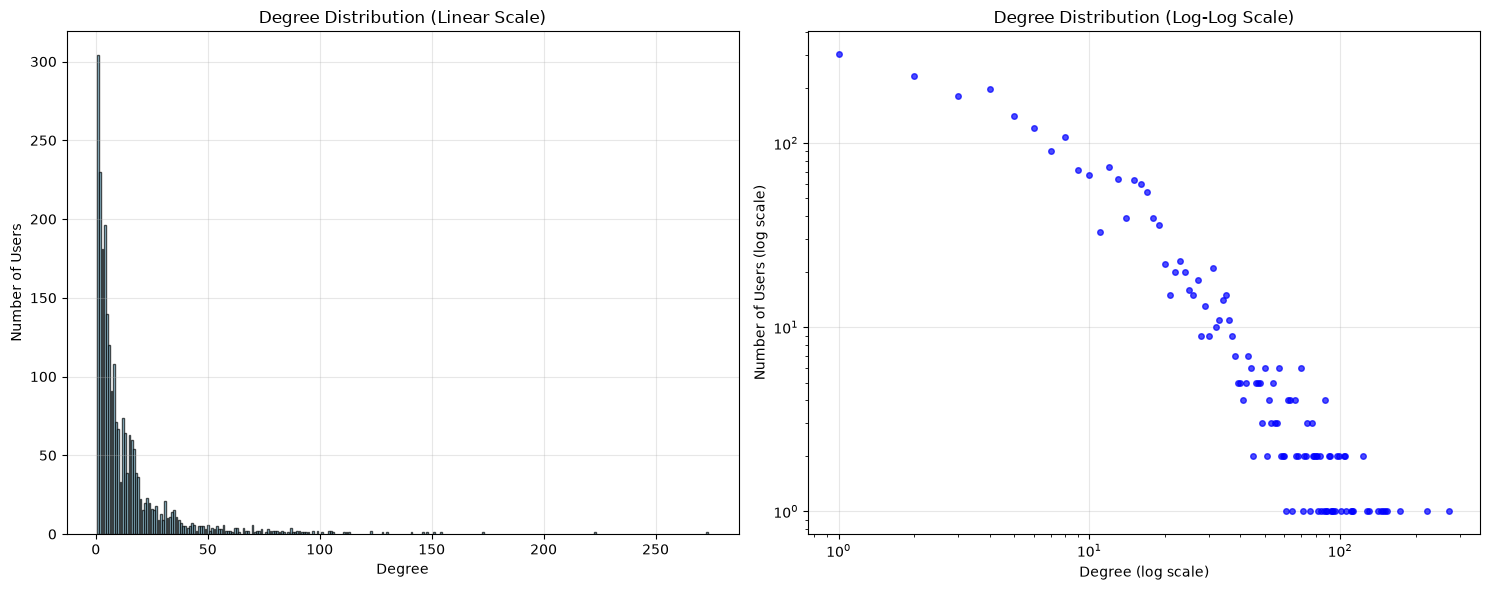


Degree Distribution Statistics:
Mean degree: 13.71
Median degree: 7.00
Max degree: 273
Min degree: 1
Standard deviation: 19.87


In [54]:
# Plot degree distribution
plot_degree_distribution(G)

## Centrality Measures Analysis

In [55]:
# Calculate centrality measures
centralities = calculate_centrality_measures(G)

Calculating centrality measures...
  - Degree centrality...
  - Betweenness centrality...
    (using sampling with k=1000 nodes)
  - Closeness centrality...
  - Eigenvector centrality...


## Top Hamsterster Users by Centrality Measures

In [64]:
# Display top users
display_top_hamsters(centralities, top_n=10)


TOP 10 HAMSTERSTER USERS BY CENTRALITY MEASURES

DEGREE CENTRALITY:
----------------------------------------
 1. User  237 - 0.112577
 2. User  238 - 0.091959
 3. User   44 - 0.071340
 4. User  168 - 0.063505
 5. User  169 - 0.062268
 6. User  137 - 0.061031
 7. User   45 - 0.060206
 8. User   46 - 0.058144
 9. User  176 - 0.053608
10. User  177 - 0.052784

BETWEENNESS CENTRALITY:
----------------------------------------
 1. User  237 - 0.057864
 2. User  169 - 0.041040
 3. User  137 - 0.041009
 4. User  251 - 0.028976
 5. User  238 - 0.028876
 6. User   44 - 0.022229
 7. User   23 - 0.020773
 8. User   65 - 0.018545
 9. User  168 - 0.016726
10. User  296 - 0.015965

CLOSENESS CENTRALITY:
----------------------------------------
 1. User  237 - 0.423427
 2. User  137 - 0.419165
 3. User  238 - 0.408793
 4. User  176 - 0.397179
 5. User  177 - 0.395998
 6. User  118 - 0.395216
 7. User   23 - 0.394514
 8. User  178 - 0.393504
 9. User    3 - 0.392345
10. User  168 - 0.391654

EIGENVECT

## Additional Analysis: Centrality Comparison

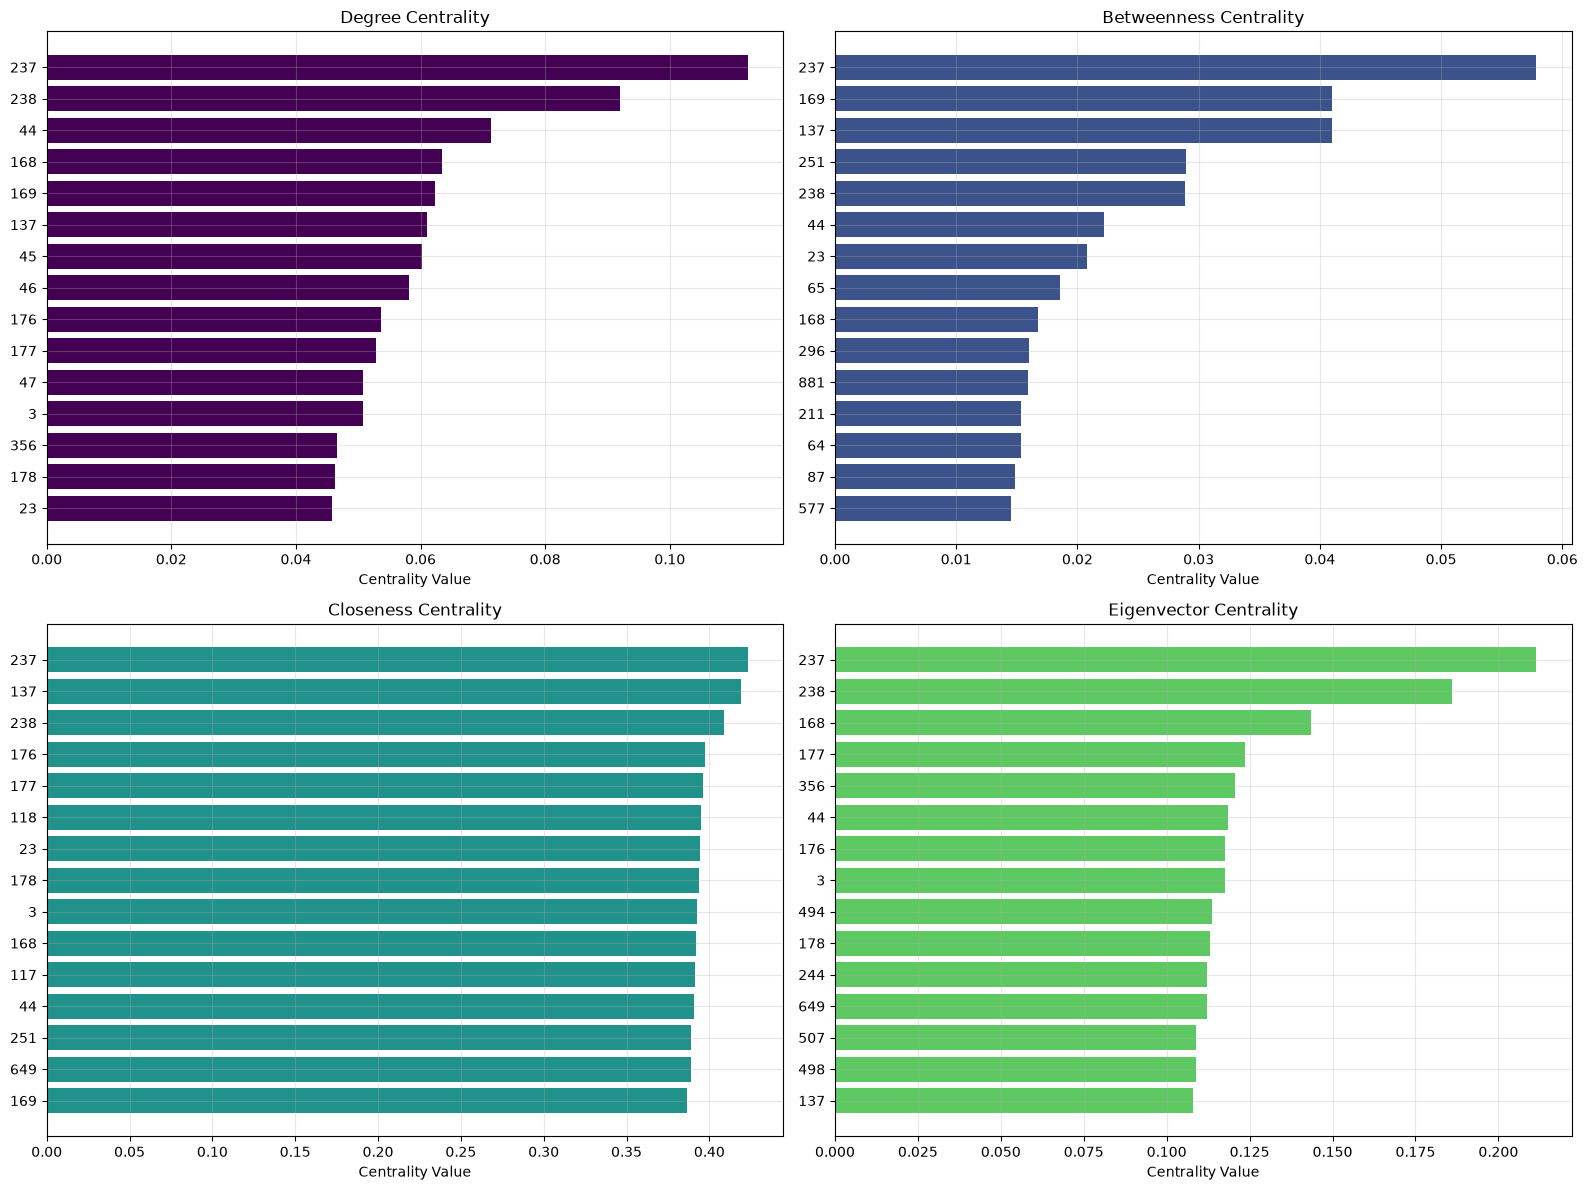

In [66]:
# Create a comparison plot of different centrality measures for top users
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

centrality_names = ['degree', 'betweenness', 'closeness', 'eigenvector']
centrality_titles = ['Degree Centrality', 'Betweenness Centrality', 'Closeness Centrality', 'Eigenvector Centrality']

for i, (name, title) in enumerate(zip(centrality_names, centrality_titles)):
    # Get top 15 users for this centrality measure
    sorted_users = sorted(centralities[name].items(), key=lambda x: x[1], reverse=True)[:15]
    users = [item[0] for item in sorted_users]
    values = [item[1] for item in sorted_users]
    
    # Create horizontal bar plot
    axes[i].barh(range(len(users)), values, color=plt.cm.viridis(i/4))
    axes[i].set_yticks(range(len(users)))
    axes[i].set_yticklabels(users)
    axes[i].set_xlabel('Centrality Value')
    axes[i].set_title(title)
    axes[i].grid(True, alpha=0.3)
    
    # Invert y-axis to show highest values at top
    axes[i].invert_yaxis()

plt.tight_layout()
plt.savefig('centrality_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

## Summary

This analysis provides comprehensive insights into the Hamsterster users relationship network:

1. **Network Structure**: The network shows typical characteristics of a real-world transportation network
2. **Degree Distribution**: Shows the connectivity patterns of users
3. **Centrality Measures**: Identify the most important users from different perspectives:
   - **Degree**: Most connected users
   - **Betweenness**: Most important bridge users
   - **Closeness**: Most centrally located users
   - **Eigenvector**: Users connected to other well-connected users

The analysis reveals major hubs like user 237, user 238, 168, 169 consistently ranking high across different centrality measures.